<a href="https://colab.research.google.com/github/MiriamSchirmer/online-harm-nlp-ws2627/blob/main/notebooks/03_Methods_Overview_Press_Releases.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Methods overview: keywords, sentiment, embeddings, BERTopic and party prediction

**Applied NLP for Online Harm Detection**, University of Konstanz, WS 2026/27

We use one small dataset for all methods: 992 press releases by members of the US Congress (496 Democrats, 496 Republicans), 31 per party and month from September 2022 to December 2023. They are a random sample from the press release data of the [Polarization Research Lab](https://polarizationresearchlab.org/).

1. Find the press releases about immigration with a keyword list, and look at how this changes over time.
2. Compare the sentiment of Democrats and Republicans.
3. Represent each press release as an embedding, map them and search them by meaning.
4. Find the topics of one party with BERTopic.
5. Predict the party from the text, and use the accuracy as a measure of polarization.

The notebook runs in a few minutes. It is faster with a GPU: **Runtime → Change runtime type → T4 GPU → Save**.

## 0. Install packages and load the data

`vaderSentiment` (sentiment) and `bertopic` (topic models) are not installed in Colab, so we install them first. This takes about a minute.

In [1]:
# vaderSentiment: dictionary-based sentiment scores
# bertopic: topic models based on embeddings
!pip install -q vaderSentiment bertopic #-q means 'quiet' - less output is printed

In [2]:
import re                         # regular expressions
import numpy as np                # 'numbers'
import pandas as pd               # tables (data frames)
import matplotlib.pyplot as plt   # plots
import seaborn as sns             # nicer plots on top of matplotlib

PARTY_COLORS = {"D": "#1f5fa8", "R": "#c0392b"}   # Democrats blue, Republicans red

We load the data from Google Drive.

1. Upload `press_releases_sample.csv` to your Google Drive, e.g. into a folder `online_harm`.
2. Run the cell and allow access to your Drive.
3. Your Drive now appears under `/content/drive/MyDrive/`. Adjust the path if your folder has a different name.

In [3]:
from google.colab import drive   # connects Colab to your Google Drive

drive.mount("/content/drive")
csv_path = "/content/drive/MyDrive/online_harm/press_releases_sample.csv"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
df = pd.read_csv(csv_path)
df["date"] = pd.to_datetime(df["date"])

print(df.shape)
df.head()

(992, 8)


,id,date,name,party,chamber,state,title,text
0,183,2022-09-02,Melanie Stansbury,D,House,NM,"Heinrich, Luján, Stansbury Welcome Over $11.3 ...",WASHINGTON – U.S. Senators Martin Heinrich (N....
1,121,2022-09-02,Sherrod Brown,D,Senate,OH,NaN,"TOLEDO, OH – Today, U.S. Senator Sherrod Brown..."
2,145,2022-09-02,Charles E. Grassley,R,Senate,IA,Q&A: 99 County Meetings,Q&A: 99 County Meetings With U.S. Senator Chuc...
3,216,2022-09-02,Gus Bilirakis,R,House,FL,Bilirakis Visits Cyber Florida and the Global ...,"Tampa, FL: Earlier today, Congressman Gus Bili..."
4,149,2022-09-02,John Hoeven,R,Senate,ND,"Hoeven, Colleagues Push Back on U.S. Marshals ...","Hoeven, Colleagues Push Back on U.S. Marshals ..."


Each row is one press release. We use the columns `party` (`D` or `R`), `name`, `date`, `title` and `text`.

In [5]:
print(df["party"].value_counts())
print() # empty line for space
print("Words per press release:")
print(df["text"].str.split().str.len().describe().round())

party
D    496
R    496
Name: count, dtype: int64

Words per press release:
count     992.0
mean      432.0
std       320.0
min        52.0
25%       213.0
50%       336.0
75%       567.0
max      1901.0
Name: text, dtype: float64


In [6]:
# one full press release
example = df.sample(1, random_state=1).iloc[0]
print(example["name"], f"({example['party']})", example["date"].date())
print(example["title"])
print()
print(example["text"][:1500])

John Sarbanes (D) 2023-07-20
Defending Your Freedom to Vote

The Freedom to Vote Act would strengthen our democracy and fight corruption. It reflects the Democratic Caucus' unwavering commitment to ensuring every American has a voice and a vote in our democracy. By designating the Freedom to Vote Act as H.R. 11 in the House and S.1 in the Senate, we are giving this bill the highest possible priority because our most fundamental freedoms are at stake. Americans have two expectations when they step into the town square of their civic engagement: that their voice and their vote will be respected and that the elected officials they send to Washington will not be corrupted by big, dark money. The Freedom to Vote Act meets those expectations. Specifically, the Freedom to Vote Act would: Expand automatic voter registration and same day registration; Strengthen vote by mail, early voting and ballot access; Combat voter intimidation and voter suppression; Protect elections from foreign interfer

## 1. Finding the press releases about immigration

Most press releases are about other things. To compare how the parties talk about immigration, we first need the press releases that are about it. The simplest method is a **keyword list** combined with a **regular expression**:

- `\b` is a word boundary: the match has to start at the beginning of a word.
- `\w*` allows any ending, so `immigr` matches *immigration*, *immigrant* and *immigrants* (but `border` also matches *borderline*).
- `(?:a|b|c)` means *a or b or c*.

In [7]:
keywords = ["immigr", "migrant", "asylum", "border", "refugee", "undocumented", "deport", "illegal alien"]
pattern = r"\b(?:immigr|migrant|asylum|border|refugee|undocumented|deport|illegal alien)\w*"
print(pattern)

df["immigration"] = df["text"].str.contains(pattern, case=False, regex=True)

print(df["immigration"].sum(), "of", len(df), "press releases contain at least one keyword")
df.groupby("party")["immigration"].mean().round(3)   # share per party

\b(?:immigr|migrant|asylum|border|refugee|undocumented|deport|illegal alien)\w*
129 of 992 press releases contain at least one keyword


,immigration
party,
D,0.107
R,0.153


How often does each keyword occur, per party?

In [8]:
counts = pd.DataFrame({
    kw: df.groupby("party")["text"].apply(lambda t: t.str.count(r"(?i)\b" + kw + r"\w*").sum())
    for kw in keywords
}).T
counts

party,D,R
immigr,167,56
migrant,22,23
asylum,6,27
border,60,370
refugee,26,8
undocumented,4,0
deport,58,5
illegal alien,0,5


### Keywords in context

Counts do not show how a word is used. A **keyword-in-context** (KWIC) list shows the words around each match. This is a quick way to find matches that are not about immigration.

Some press releases appear almost twice: members of Congress often send out the same text.

In [36]:
def kwic(texts, word, window=60, n=10):
    # print up to n matches of word, with window characters on each side
    shown = 0
    for text in texts:
        for m in re.finditer(r"(?i)\b" + word + r"\w*", text):
            left = text[max(0, m.start() - window):m.start()]
            right = text[m.end():m.end() + window]
            print(f"...{left:>{window}} [{m.group()}] {right}...")
            shown += 1
            if shown >= n:
                return

kwic(df["text"], "border")

...e the luxury of ignoring this problem. "An average of 6,000  [migrants]  cross the southern border every day, and yet the Mayor of W...
...to us.’” “Well, that's why maybe, just maybe, the fact that  [migrants]  are showing up in Washington, D.C., New York, and Chicago s...
... way, the Biden Administration has been shipping and flying  [migrants]  into the interior of the United States for the last year an...
... States for the last year and a half.” “An average of 6,000  [migrants]  cross the southern border every day, and yet the Mayor of W...
...providing education, health, and safety-related services to  [migrants]  from the Freely Associated States of Palau, the Marshall Is...
...he Administration develops a plan to handle the anticipated  [migrant]  surge once Title 42 is repealed. I will continue to work wi...
...l for U.S. Customs and Border Patrol (CBP) to quickly expel  [migrants]  crossing the border illegally. BACKGROUND: The Public Healt...
...nce Over $900,000 Coming 

`border` also catches *cross-border trade* or *the Ukrainian border*. The keyword list decides what you measure, so check the matches like this and adjust the list.

### Over time

For each quarter, we compute the share of press releases with an immigration keyword.

Note: A timeline like this only works if there are enough texts in every period and the periods are covered evenly.

The dashed line marks the end of *Title 42* (11 May 2023), the pandemic rule that allowed fast expulsions at the border.

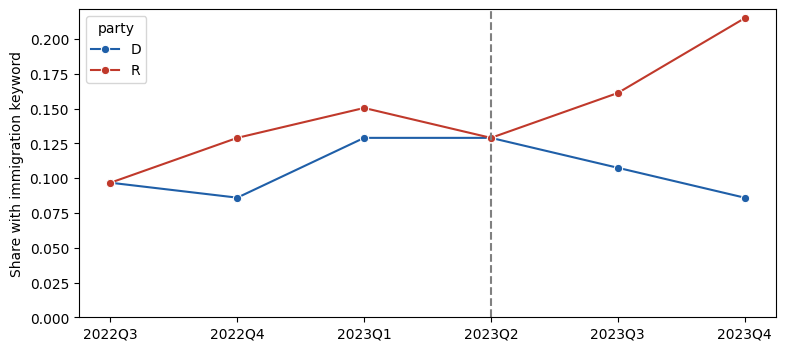

party,D,R
quarter,,
2022Q3,0.10,0.10
2022Q4,0.09,0.13
2023Q1,0.13,0.15
2023Q2,0.13,0.13
2023Q3,0.11,0.16
2023Q4,0.09,0.22


In [10]:
df["quarter"] = df["date"].dt.to_period("Q").astype(str)
per_quarter = df.groupby(["quarter", "party"])["immigration"].mean().reset_index()

plt.figure(figsize=(9, 4))
sns.lineplot(data=per_quarter, x="quarter", y="immigration", hue="party", palette=PARTY_COLORS, marker="o")
plt.axvline("2023Q2", color="grey", linestyle="--")
plt.ylim(bottom=0)
plt.ylabel("Share with immigration keyword")
plt.xlabel("")
plt.show()

per_quarter.pivot(index="quarter", columns="party", values="immigration").round(2)

With 93 press releases per party and quarter, two more texts with a keyword change the share by about 2 percentage points, so small differences are noise.

## 2. Sentiment: comparing the parties

We use **VADER**, a dictionary-based sentiment tool. Each word in its lexicon has a score; VADER adds them up (with rules for negation, words like *very*, capital letters, etc.) and returns a **compound score** between -1 (very negative) and +1 (very positive).

We score both the full text and the title. VADER was built for short social media posts: on long press releases the word scores add up, and most texts end up close to -1 or +1. The titles are short, so their scores spread out more. The plots and the test below therefore use the **title scores**.

In [11]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer   # the VADER sentiment dictionary

vader = SentimentIntensityAnalyzer()

print(vader.polarity_scores("We will secure the border."))
print(vader.polarity_scores("This border crisis is a disaster and a failure."))

{'neg': 0.0, 'neu': 0.625, 'pos': 0.375, 'compound': 0.34}
{'neg': 0.657, 'neu': 0.343, 'pos': 0.0, 'compound': -0.91}


In [12]:
# compound score for the full text and for the title
df["sentiment"] = df["text"].apply(lambda t: vader.polarity_scores(t)["compound"])
df["sentiment_title"] = df["title"].fillna("").apply(lambda t: vader.polarity_scores(t)["compound"])

# mean sentiment per party, for immigration (True) and other press releases (False)
df.groupby(["immigration", "party"])[["sentiment", "sentiment_title"]].mean().round(2)

sentiment  sentiment_title
immigration party                            
False       D           0.64             0.10
            R           0.57             0.08
True        D           0.65             0.17
            R           0.03             0.01

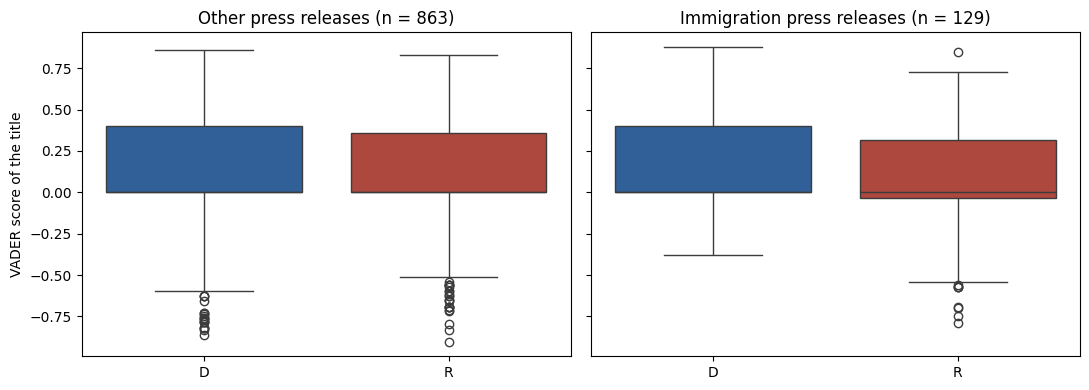

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (is_imm, label) in zip(axes, [(False, "Other press releases"), (True, "Immigration press releases")]):
    sub = df[df["immigration"] == is_imm]
    sns.boxplot(data=sub, x="party", y="sentiment_title", hue="party", palette=PARTY_COLORS,
                order=["D", "R"], legend=False, ax=ax)
    ax.set_title(f"{label} (n = {len(sub)})")
    ax.set_xlabel("")
axes[0].set_ylabel("VADER score of the title")
plt.tight_layout()
plt.show()

Is the difference between the parties larger than we would expect by chance? We use the **Mann-Whitney U test**.

Why not a t-test? The t-test compares means and assumes roughly normally distributed values. The title scores are not: many titles get exactly 0 (no word from the VADER lexicon), and the others spread between -1 and +1. The Mann-Whitney U test does not use the values, only their **ranks**: it sorts all titles from most negative to most positive and checks whether the titles of one party are systematically higher in this ranking.

In [14]:
from scipy.stats import mannwhitneyu   # SciPy: statistical tests

imm = df[df["immigration"]]
d = imm.loc[imm["party"] == "D", "sentiment_title"]
r = imm.loc[imm["party"] == "R", "sentiment_title"]

print(f"Mean title sentiment, immigration press releases: D = {d.mean():.2f}, R = {r.mean():.2f}")
result = mannwhitneyu(d, r)
print(result)
print(f"Share of pairs in which the Democratic title is more positive: {result.statistic / (len(d) * len(r)):.2f}")

Mean title sentiment, immigration press releases: D = 0.17, R = 0.01
MannwhitneyuResult(statistic=np.float64(2480.5), pvalue=np.float64(0.022392757564881773))
Share of pairs in which the Democratic title is more positive: 0.62


Do the scores match how we read them? Let's look at the most negative and most positive titles.

In [39]:
cols = ["party", "name", "title", "sentiment_title"]
display(imm.sort_values("sentiment_title")[cols].head(8))
display(imm.sort_values("sentiment_title", ascending=False)[cols].head(8))


,party,name,title,sentiment_title
4,R,John Hoeven,"Hoeven, Colleagues Push Back on U.S. Marshals Service's Proposal to Release Criminal Illegal Immigrants Into U.S.",-0.7906
532,R,Christopher H. Smith,"Humanitarian crisis at border worsens with record-setting 10,300 migrants apprehended in just one day Smith presses top Biden official tasked with combating human trafficking on massive screening gaps at the border",-0.7506
41,R,John Cornyn,Cornyn: Will Democrat Mayors Finally Force Biden to Take Border Crisis Seriously?,-0.7003
73,R,Kevin McCarthy,One Pill Can Kill,-0.6908
830,R,Sam Graves,Chaos,-0.5719
820,R,Andy Biggs,Daily Caller: Congress Cant Continue The Budget Insanity. Were Standing Against A Continuing Resolution,-0.5719
732,R,Tom Cole,Continued Chaos at the Southern Border,-0.5719
77,R,Robert E. Latta,"Latta, Bilirakis, Joyce Lead Opposition to California Gas-Powered Vehicle Ban",-0.5574


,party,name,title,sentiment_title
623,D,Henry Cuellar,Rep. Cuellar Secures Language Strengthening Migrant Facility Video Monitoring and Consolidating Migrant Medical Care in FY24 Homeland Security Appropriations Bill,0.8779
390,R,Bill Huizenga,"Bipartisan Call: Huizenga, Higgins Ask President Biden to Push for Greater Canadian Commitment on Great Lakes",0.8481
601,D,Pramila Jayapal,Jayapal Statement on Supreme Court Decision in United States v. Texas,0.7506
592,R,Steve Womack,"Womack Votes to Secure Southern Border, Strengthen National Security",0.7269
991,R,Ted Cruz,Sen. Cruz: Another Great Year of Fighting and Winning for Texans,0.7184
981,D,Veronica Escobar,Congresswoman Escobar Announces EDA FY23 Grant Award to City of El Paso,0.7184
593,D,Raja Krishnamoorthi,"Rep. Krishnamoorthi, Sen. Durbin, And Rep. Norman Applaud DHS For Establishing The Homeland Security Academic Partnership Council",0.6597
680,D,Ayanna Pressley,"WATCH: At NAACP Convention, Pressley Delivers Love Letter to Black Boston",0.6369


Sentiment measures tone, not hostility towards a group: a press release can be very negative about the government's border policy without saying anything negative about migrants.

VADER is only one option. **You can also fine-tune a BERT-based sentiment model (as in section 5) or ask an LLM such as Qwen (Session 4), and compare the results.** To say which model is right, you need annotated data: label a sample of texts yourself, then compute agreement, precision, recall and F1 for each model, as in Session 4.

## 3. Embeddings

Keywords only find the words we thought of. **Sentence embeddings** turn each text into a vector of numbers, so that texts with a similar meaning are close to each other, even if they use different words.

We use [`all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) from the `sentence-transformers` library (already installed in Colab). It is small and fast and gives 384 numbers per text.

`all-MiniLM-L6-v2` is a small BERT: it has the same architecture and tokenizer as BERT, but 6 layers instead of 12 and 384 instead of 768 numbers per token.

Like all BERT variants, it only reads the first 256 tokens (roughly 180 words) of each text, so for long press releases the embedding mostly reflects the beginning.

In [17]:
from sentence_transformers import SentenceTransformer   # loads embedding models from Hugging Face

model = SentenceTransformer("all-MiniLM-L6-v2")
docs = (df["title"].fillna("") + ". " + df["text"]).tolist()   # title + text

embeddings = model.encode(docs, show_progress_bar=True, normalize_embeddings=True)
embeddings.shape   # (number of texts, 384)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/31 [00:00<?, ?it/s]

(992, 384)

### Similarity between texts

We compare two embeddings with the **cosine similarity**: 1 means the same direction (very similar), values around 0 mean unrelated. Because we normalised the vectors, the cosine similarity is simply the dot product (`@`).

In [18]:
sentences = [
    "We must secure our southern border and stop illegal crossings.",
    "The migrant crisis at the border is out of control.",
    "Asylum seekers deserve a fair and humane process.",
    "This bill lowers the cost of insulin for seniors.",
]
emb = model.encode(sentences, normalize_embeddings=True)
pd.DataFrame(emb @ emb.T, index=[s[:35] for s in sentences], columns=[1, 2, 3, 4]).round(2)

,1,2,3,4
We must secure our southern border,1.00,0.47,0.32,0.06
The migrant crisis at the border is,0.47,1.00,0.34,-0.01
Asylum seekers deserve a fair and h,0.32,0.34,1.00,0.01
This bill lowers the cost of insuli,0.06,-0.01,0.01,1.00


### A map of all press releases

**UMAP** reduces the 384 dimensions to 2, so we can plot them. Texts that are close on the map are similar. The exact distances on such a map should not be over-interpreted.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


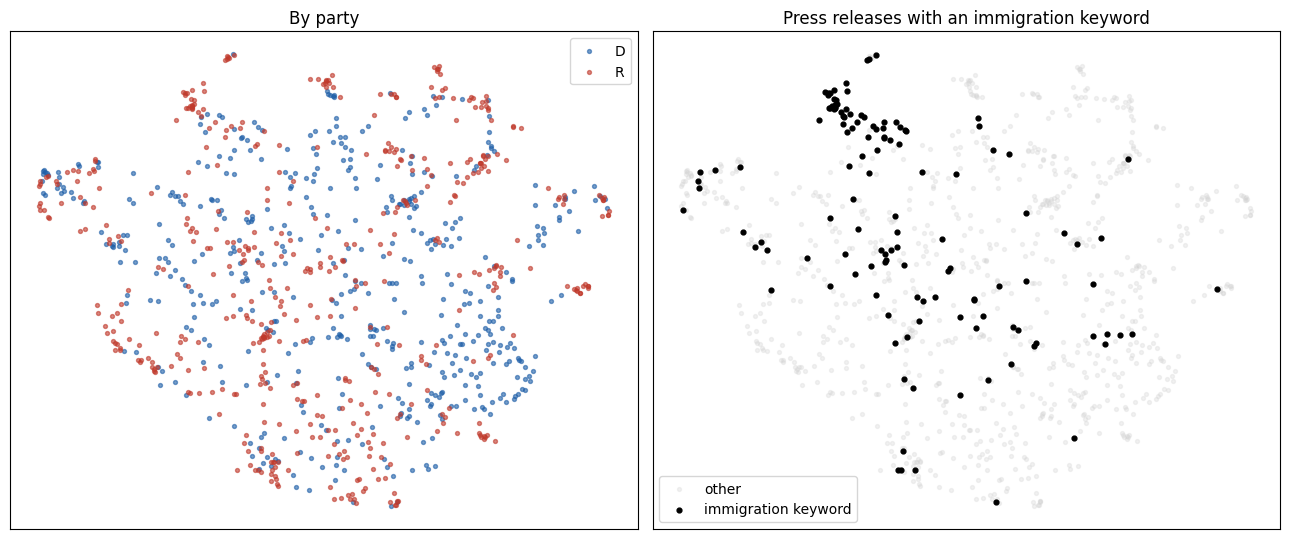

In [19]:
from umap import UMAP   # reduces many dimensions to 2 for plotting

coords = UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42).fit_transform(embeddings)
df["x"], df["y"] = coords[:, 0], coords[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for party, color in PARTY_COLORS.items():
    sub = df[df["party"] == party]
    axes[0].scatter(sub["x"], sub["y"], s=8, alpha=0.6, color=color, label=party)
axes[0].set_title("By party")
axes[0].legend()

axes[1].scatter(df["x"], df["y"], s=8, alpha=0.3, color="lightgrey", label="other")
sub = df[df["immigration"]]
axes[1].scatter(sub["x"], sub["y"], s=12, color="black", label="immigration keyword")
axes[1].set_title("Press releases with an immigration keyword")
axes[1].legend()

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Are press releases more similar to those of the same party than to those of the other party? We compute the mean similarity within and between the parties, for all press releases and for the immigration press releases only.

In [20]:
def party_similarity(mask):
    e = embeddings[mask.to_numpy()]
    p = df.loc[mask, "party"].to_numpy(dtype=str)
    s = e @ e.T
    np.fill_diagonal(s, np.nan)   # ignore the similarity of a text with itself
    return pd.Series({
        "within D": np.nanmean(s[p == "D"][:, p == "D"]),
        "within R": np.nanmean(s[p == "R"][:, p == "R"]),
        "between D and R": np.nanmean(s[p == "D"][:, p == "R"]),
    }).round(3)

pd.DataFrame({
    "all": party_similarity(df["party"].notna()),
    "immigration": party_similarity(df["immigration"]),
})

,all,immigration
within D,0.238,0.299
within R,0.241,0.373
between D and R,0.231,0.301


### EXTRA INPUT: Searching by meaning

Instead of a keyword list, we can describe in a sentence what we are looking for (a **query**) and find the press releases that are closest to it:

1. The query is turned into an embedding by the same model. It is now a point in the same space as the 992 press releases.
2. We compute the cosine similarity between the query and every press release, as in the small table above. This gives one number per press release.
3. We sort the press releases by this number. The top results are closest in meaning to the query, even if they use different words.

The column `immigration` shows whether the keyword list found the text. The similarity is only useful for ranking: there is no fixed value above which a text "is about" immigration.

In [40]:
def search(query, n=10):
    q = model.encode([query], normalize_embeddings=True)[0]   # 1. the query becomes an embedding (384 numbers)
    similarity = embeddings @ q                                # 2. cosine similarity with every press release
    out = df.assign(similarity=similarity).sort_values("similarity", ascending=False)   # 3. most similar first
    return out[["party", "title", "immigration", "similarity"]].head(n)

search("illegal immigration and the crisis at the southern border")

,party,title,immigration,similarity
502,R,House GOP Leadership’s Statement on the Introduction of the Secure the Border Act,True,0.621648
722,R,Every State is a Border State,True,0.597641
535,R,Blaines Bulletin: The Secure the Border Act of 2023,True,0.593944
830,R,Chaos,True,0.584918
732,R,Continued Chaos at the Southern Border,True,0.577173
798,R,It’s not a talking point,True,0.554287
527,R,Burgess Votes to Secure the Border,True,0.554225
244,R,"New Year, New Majority",True,0.550732
331,R,"Capito, Manchin, Colleagues Offer Solutions to Solve Border Crisis Read More",True,0.548695
529,R,McHenry Votes to Secure the Border,True,0.548050


## 4. BERTopic

**BERTopic** groups the embeddings into clusters and describes each cluster by its most typical words (with a class-based TF-IDF). We run it on the Republican press releases and reuse the embeddings from section 3, so it only takes a few seconds.

With 496 texts the topics are rough; topic models work better with more data.

In [23]:
from bertopic import BERTopic                                  # topic models based on embeddings
from sklearn.feature_extraction.text import CountVectorizer   # counts the words that describe each topic

party = "R"   # change to "D" to compare
mask = (df["party"] == party).to_numpy()
party_docs = [d for d, m in zip(docs, mask) if m]

topic_model = BERTopic(
    embedding_model=model,   # the MiniLM model from section 3, needed to embed search queries in find_topics
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42),
    vectorizer_model=CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2),   # words that describe the topics
    min_topic_size=8,   # smallest number of texts per topic
)
topics, _ = topic_model.fit_transform(party_docs, embeddings[mask])

topic_model.get_topic_info().head(15)

,Topic,Count,Name,Representation,Representative_Docs
0,-1,115,-1_said_congressman_house_act,"[said, congressman, house, act, committee, fen...","[Latta, Bilirakis, Joyce Lead Opposition to Ca..."
1,0,38,0_border_children_secure_biden,"[border, children, secure, biden, trafficking,...",[Womack Votes to Secure Southern Border. Washi...
2,1,35,1_veterans_health_care_alzheimer,"[veterans, health, care, alzheimer, act, benef...",[ICYMI: Stefanik Op-ed in Sun Community News: ...
3,2,31,2_veterans_day_george_truman,"[veterans, day, george, truman, honor, war, vi...","[Wagner, Blunt, Missouri Congressional Delegat..."
4,3,29,3_energy_climate_american_biden,"[energy, climate, american, biden, gas, prices...",[Weekly Column: Republicans Want to Lower Pric...
5,4,27,4_debt_spending_budget_trillion,"[debt, spending, budget, trillion, government,...",[Blaine's Bulletin: The Debt Ceiling. I hope y...
6,5,26,5_israel_iran_hamas_antisemitism,"[israel, iran, hamas, antisemitism, resolution...",[Smith hearing exposes rampant antisemitism an...
7,6,22,6_house_biden_republicans_speaker,"[house, biden, republicans, speaker, congress,...","[1 Step Forward 2 Steps Back. Since day one, H..."
8,7,20,7_idaho_simpson_project_funding,"[idaho, simpson, project, funding, dairy, rep ...",[Rep. Simpsons Latest Community Project Fundin...
9,8,18,8_000_development_river_griffith,"[000, development, river, griffith, grant, vir...",[Congressman Griffith's Weekly E-Newsletter 10...


Topic `-1` contains the outliers: texts that do not fit into any topic.

In [24]:
topic_model.visualize_barchart(top_n_topics=12, n_words=6)

### Visualizing the topics

`visualize_topics` draws each topic as a circle: the bigger the circle, the more texts it contains, and topics that are close to each other use similar words. `visualize_documents` shows each press release as a dot, coloured by its topic; we reuse the 2D map from section 3, so it is fast. Both plots are interactive: hover over them to see the words and titles.

In [25]:
topic_model.visualize_topics()

In [26]:
party_coords = df.loc[mask, ["x", "y"]].to_numpy()   # the UMAP map from section 3
party_titles = df.loc[mask, "title"].fillna("").tolist()   # shown when you hover over a dot

topic_model.visualize_documents(party_titles, reduced_embeddings=party_coords, hide_annotations=True)

To compare, set `party = "D"` and run the BERTopic cells again. The topics change with settings such as `min_topic_size`, so report them in your project.

## 5. Predicting the party as a measure of polarization

If a classifier can tell from a text alone which party wrote it, the two parties use different language. Peterson and Spirling (2018) use the **accuracy** of such a classifier as a measure of polarization: the better it predicts the party, the more polarized the language.

This is a **binary classification** task: there are exactly two classes, `D` and `R`, and each press release gets one of them. Our data has as many Democrats as Republicans, so guessing gives 50% accuracy. Values close to 50% mean the parties sound alike; values close to 100% mean their language is clearly separated.

We use **TF-IDF** features (word counts, weighted down for words that occur in many texts) and a **logistic regression**. With **5-fold cross-validation**, the data is split into five parts: the model is trained on four and tested on the fifth, five times. So it is always tested on texts it has not seen.

In [29]:
# scikit-learn: classic machine learning
from sklearn.feature_extraction.text import TfidfVectorizer   # texts -> TF-IDF features
from sklearn.linear_model import LogisticRegression           # the classifier
from sklearn.pipeline import make_pipeline                    # chains both steps
from sklearn.model_selection import cross_val_score           # cross-validation

def party_accuracy(texts, labels):
    clf = make_pipeline(
        TfidfVectorizer(stop_words="english", min_df=2),
        LogisticRegression(max_iter=1000),
    )
    return cross_val_score(clf, texts, labels, cv=5, scoring="accuracy").mean()

print(f"All press releases:         {party_accuracy(df['text'], df['party']):.2f}")
print(f"Immigration press releases: {party_accuracy(imm['text'], imm['party']):.2f}   (n = {len(imm)})")

All press releases:         0.83
Immigration press releases: 0.74   (n = 129)


Which words does the classifier use? We train it once on all texts and look at the words with the largest weights in each direction.

In [30]:
clf = make_pipeline(TfidfVectorizer(stop_words="english", min_df=2), LogisticRegression(max_iter=1000))
clf.fit(df["text"], df["party"])

words = clf[0].get_feature_names_out()
weights = clf[1].coef_[0]   # positive: points to R, negative: points to D

print("Typical for Republicans:", ", ".join(words[np.argsort(weights)[-20:][::-1]]))
print()
print("Typical for Democrats:  ", ", ".join(words[np.argsort(weights)[:20]]))

Typical for Republicans: smith, border, idaho, biden, simpson, womack, burgess, griffith, mccarthy, rural, spending, energy, china, luetkemeyer, veterans, congressman, chairman, huizenga, fentanyl, policies

Typical for Democrats:   marianas, congresswoman, ca, program, sherman, violence, pressley, democratic, workers, community, donald, funding, health, families, housing, democracy, ma, maga, million, pelosi


### Over time

We compute the accuracy separately for each quarter. Each quarter has only 186 texts (62 in 2022Q3), so expect some noise.

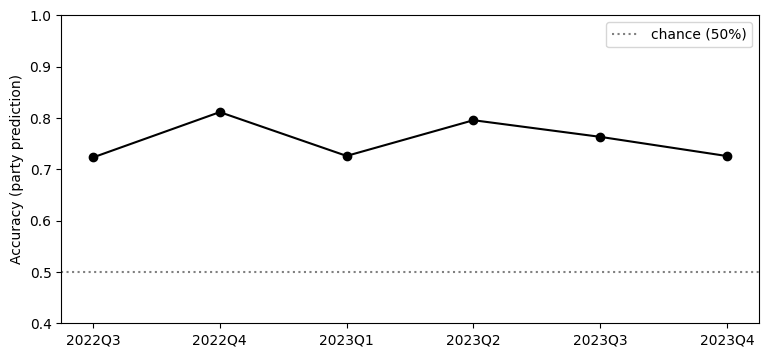

,0
2022Q3,0.72
2022Q4,0.81
2023Q1,0.73
2023Q2,0.80
2023Q3,0.76
2023Q4,0.73


In [31]:
acc = pd.Series({q: party_accuracy(g["text"], g["party"]) for q, g in df.groupby("quarter")})

plt.figure(figsize=(9, 4))
plt.plot(acc.index, acc.values, marker="o", color="black")
plt.axhline(0.5, color="grey", linestyle=":", label="chance (50%)")
plt.ylim(0.4, 1)
plt.ylabel("Accuracy (party prediction)")
plt.legend()
plt.show()

acc.round(2)

### Embeddings instead of words

We can use the embeddings from section 3 as features instead of TF-IDF.

In [32]:
emb_acc = cross_val_score(LogisticRegression(max_iter=1000), embeddings, df["party"], cv=5).mean()
print(f"Accuracy with embeddings: {emb_acc:.2f}")

Accuracy with embeddings: 0.74


### Fine-tuning BERT

In the previous examples, the embeddings are calculated once and stay fixed: only the logistic regression on top of them learns. When we **fine-tune** a BERT model, all its weights are trained further on our task, so the model adapts to the language of press releases and to the party labels.

We use [`distilbert-base-uncased`](https://huggingface.co/distilbert/distilbert-base-uncased), a smaller and faster version of BERT (6 instead of 12 layers). Fine-tuning works in these steps:

1. **Tokenize**: the tokenizer cuts each press release into subword tokens and turns them into numbers (IDs). Texts longer than 256 tokens are cut off.
2. **Add a classification head**: `AutoModelForSequenceClassification` takes the pretrained BERT and puts a small new layer on top. This layer reads the vector of the first token (`[CLS]`), which summarizes the text, and gives one score per class. We set `num_labels=2` because this is a binary task: `D` (label 0) or `R` (label 1). At the start, this new layer is random.
3. **Train**: the model predicts the party for a batch of 16 training texts. The **loss** (cross-entropy) measures how far the predictions are from the true labels. The weights are then changed a little to make the loss smaller, both in the new layer and in all BERT layers. This is repeated for all batches; one pass through all training texts is an **epoch**, and we do 3.
4. **Predict**: for a new text, the model gives two scores, and the higher one is the predicted party.

This is the same logic as the logistic regression in Session 4 (features, weights, loss, small updates), but BERT also learns the features themselves.

Fine-tuning five times for cross-validation would take too long, so we use a single split instead: we train on 80% of the press releases and test on the other 20%. For a fair comparison, we evaluate TF-IDF and the embeddings on the same split.

This needs the GPU (about one minute on a T4).

In [33]:
from sklearn.model_selection import train_test_split   # split the data into training and test set
from sklearn.metrics import accuracy_score              # share of correct predictions

train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["party"], random_state=42)
print(len(train_df), "training texts,", len(test_df), "test texts")

# TF-IDF and embeddings on the same split
clf.fit(train_df["text"], train_df["party"])
tfidf_acc = accuracy_score(test_df["party"], clf.predict(test_df["text"]))

emb_clf = LogisticRegression(max_iter=1000).fit(embeddings[train_df.index], train_df["party"])
emb_acc = accuracy_score(test_df["party"], emb_clf.predict(embeddings[test_df.index]))

793 training texts, 199 test texts


In [34]:
import torch                       # deep learning library that runs the model (on the GPU if there is one)
from datasets import Dataset       # Hugging Face format for training data
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,   # Hugging Face: load and train BERT-type models
                          DataCollatorWithPadding, TrainingArguments, Trainer)

bert_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(bert_name)
label2id = {"D": 0, "R": 1}   # binary task: two classes, as numbers

def to_dataset(d):
    ds = Dataset.from_dict({"text": d["text"].tolist(), "label": d["party"].map(label2id).tolist()})
    return ds.map(lambda batch: tokenizer(batch["text"], truncation=True, max_length=256), batched=True)

train_ds, test_ds = to_dataset(train_df), to_dataset(test_df)

# pretrained DistilBERT + a new classification layer with 2 outputs (D, R)
bert = AutoModelForSequenceClassification.from_pretrained(bert_name, num_labels=2)

args = TrainingArguments(
    output_dir="party_bert",
    num_train_epochs=3,                  # three passes through the training data
    per_device_train_batch_size=16,      # 16 texts per weight update
    learning_rate=5e-5,                  # how big each weight update is
    fp16=torch.cuda.is_available(),      # faster on the GPU
    save_strategy="no",
    report_to="none",
    logging_steps=20,
)
trainer = Trainer(model=bert, args=args, train_dataset=train_ds,
                  data_collator=DataCollatorWithPadding(tokenizer))
trainer.train()   # the loss printed below should go down

Map:   0%|          | 0/793 [00:00<?, ? examples/s]

Map:   0%|          | 0/199 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
20,0.683478
40,0.633987
60,0.447037
80,0.346922
100,0.207405
120,0.124089
140,0.100075


TrainOutput(global_step=150, training_loss=0.346355238755544, metrics={'train_runtime': 19.6429, 'train_samples_per_second': 121.113, 'train_steps_per_second': 7.636, 'total_flos': 157569970701312.0, 'train_loss': 0.346355238755544, 'epoch': 3.0})

### TF-IDF or BERT?

**TF-IDF + logistic regression**

- Fast: trains in a second, no GPU needed.
- Easy to interpret: we can list the words that point to each party (as above).
- Works well with little data.
- But: it only counts words. It does not know that *border* and *frontier* are similar, and it ignores word order (*not good* and *good* look almost the same).

**Fine-tuned BERT**

- Understands context and meaning: similar words and word order matter.
- Often more accurate, especially with more training data.
- But: slow, needs a GPU, and reads only the first part of each text (here 256 tokens).
- Hard to interpret: we cannot simply list the words it uses.
- Results change with settings (learning rate, epochs) and between runs. With small data it can be worse than TF-IDF.

### Note: BERT only reads the beginning of a text

BERT models can read at most 512 tokens; we set the limit to 256 so that training is faster. Everything after that is cut off. About 256 tokens are roughly 180 words, and 81% of our press releases are longer than that (43% are longer than about 380 words, i.e. 512 tokens). So the model decides mostly based on the first paragraph. TF-IDF, in contrast, uses the whole text.

Ways around this:

- Split long texts into parts, classify each part and combine the results (e.g. majority vote).
- Use a model built for longer inputs, e.g. [ModernBERT](https://huggingface.co/answerdotai/ModernBERT-base) (up to 8,192 tokens).

### Another option: an LLM

Instead of training a classifier, we could also ask an LLM such as Qwen (see the Session 4 notebook) to guess the party, e.g. with the prompt *"Was this press release written by a Democrat or a Republican? Answer with D or R."* and compare its answers with the true labels.

- No training data needed (zero-shot), and LLMs can read much longer texts.
- But: much slower (one text after the other), the answers have to be parsed, and the model may know some members of Congress by name. It may also have seen some of these press releases during training.

### Comparison: TF-IDF and BERT

We compare the models on the same test set (20% of the press releases, not used in training). Besides the accuracy we report the **F1 score** (macro, i.e. the average of the F1 for D and for R), as in Session 4. With balanced classes, both give similar values.

A high accuracy does not always mean polarized language: names of members of Congress, states or a standard closing sentence can also give away the party (see the typical words above). With 199 test texts, one prediction more or less changes the accuracy by 0.5 percentage points.

Peterson, A., & Spirling, A. (2018). Classification accuracy as a substantive quantity of interest: Measuring polarization in Westminster systems. *Political Analysis*, 26(1), 120–128.

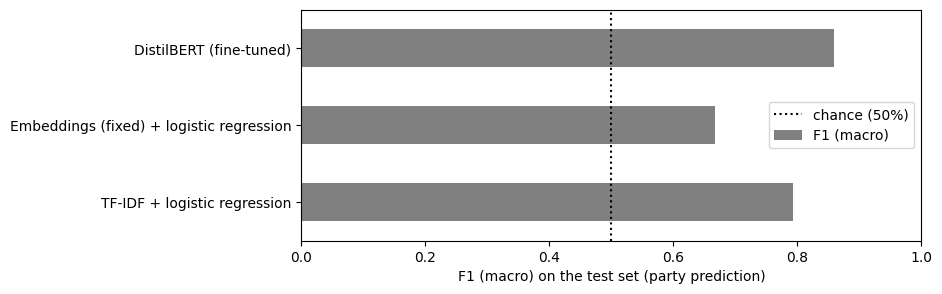

,accuracy,F1 (macro)
TF-IDF + logistic regression,0.79,0.79
Embeddings (fixed) + logistic regression,0.67,0.67
DistilBERT (fine-tuned),0.86,0.86


In [41]:
from sklearn.metrics import f1_score

bert_pred = trainer.predict(test_ds).predictions.argmax(axis=1)   # 0 or 1
id2label = {0: "D", 1: "R"}

y_true = test_df["party"].to_numpy()
predictions = {
    "TF-IDF + logistic regression": clf.predict(test_df["text"]),
    "Embeddings (fixed) + logistic regression": emb_clf.predict(embeddings[test_df.index]),
    "DistilBERT (fine-tuned)": np.array([id2label[p] for p in bert_pred]),
}

results = pd.DataFrame({
    name: {"accuracy": accuracy_score(y_true, pred), "F1 (macro)": f1_score(y_true, pred, average="macro")}
    for name, pred in predictions.items()
}).T

results["F1 (macro)"].plot.barh(color="grey", figsize=(8, 3))
plt.axvline(0.5, color="black", linestyle=":", label="chance (50%)")
plt.xlim(0, 1)
plt.xlabel("F1 (macro) on the test set (party prediction)")
plt.legend()
plt.show()

results.round(2)